##Loading DataSET

In [ ]:
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
#Checking the version of tensorflow
tf.__version__

'2.18.0'

In [ ]:
#Load the data
Fashion_MNIST=keras.datasets.fashion_mnist

(X_train_full, y_train_full),(X_test,y_test)=Fashion_MNIST.load_data()

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
#Pixels values are in the range (0-255) so if we need to normalize that we should divide
## by 255 and the output of this process will give (0-1) values
X_valid,X_train=X_train_full[:5000]/255.0,X_train_full[5000:]/255.0
y_valid,y_train=y_train_full[:5000],y_train_full[5000:]
X_test=X_test/255.0

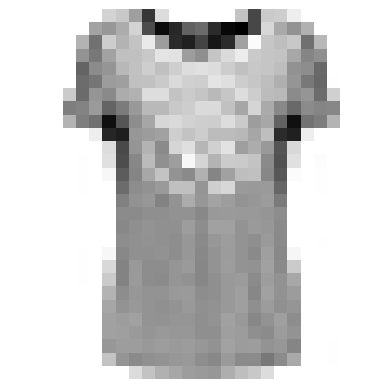

In [ ]:
plt.imshow(X_train[1],cmap="binary")
plt.axis("off")
plt.show()

In [ ]:
#lets setup classes names
#10 classes
class_names=["T-shirt/top","Trouser","Pullover","Dress","Coat","Sandal","Shirt","Sneaker","Bag","Ankle boot"]

In [ ]:
class_names[y_train[1]]

'T-shirt/top'

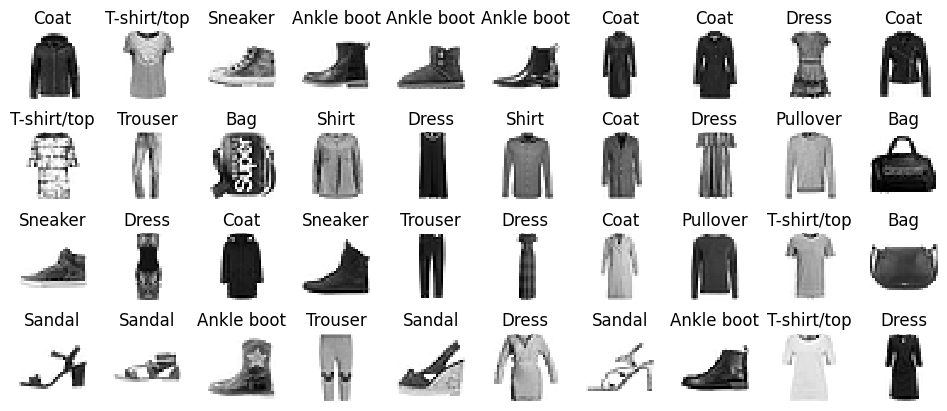

In [ ]:
n_rows=4
n_cols=10
plt.figure(figsize=(n_cols*1.2,n_rows*1.2))
for row in range(n_rows):
  for col in range(n_cols):
    index=n_cols*row+col
    plt.subplot(n_rows,n_cols,index+1)
    plt.imshow(X_train[index],cmap="binary",interpolation="nearest")
    plt.axis("off")
    plt.title(class_names[y_train[index]],fontsize=12)
plt.subplots_adjust(wspace=0.2,hspace=0.5)
plt.show()


##COnstruct the model for train

In [ ]:
model=keras.models.Sequential()
model.add(keras.layers.Flatten(input_shape=[28, 28]))
model.add(keras.layers.Dense(300,activation="relu"))
model.add(keras.layers.Dense(100,activation="relu"))
model.add(keras.layers.Dense(10,activation="softmax")) #Output (have 10 classes )

/usr/local/lib/python3.11/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [ ]:
keras.backend.clear_session()
np.random.seed(42)

In [ ]:
model.layers

[<Flatten name=flatten, built=True>,
 <Dense name=dense, built=True>,
 <Dense name=dense_1, built=True>,
 <Dense name=dense_2, built=True>]

In [ ]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 300)            │       235,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 100)            │        30,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 266,610 (1.02 MB)

 Trainable params: 266,610 (1.02 MB)

 Non-trainable params: 0 (0.00 B)

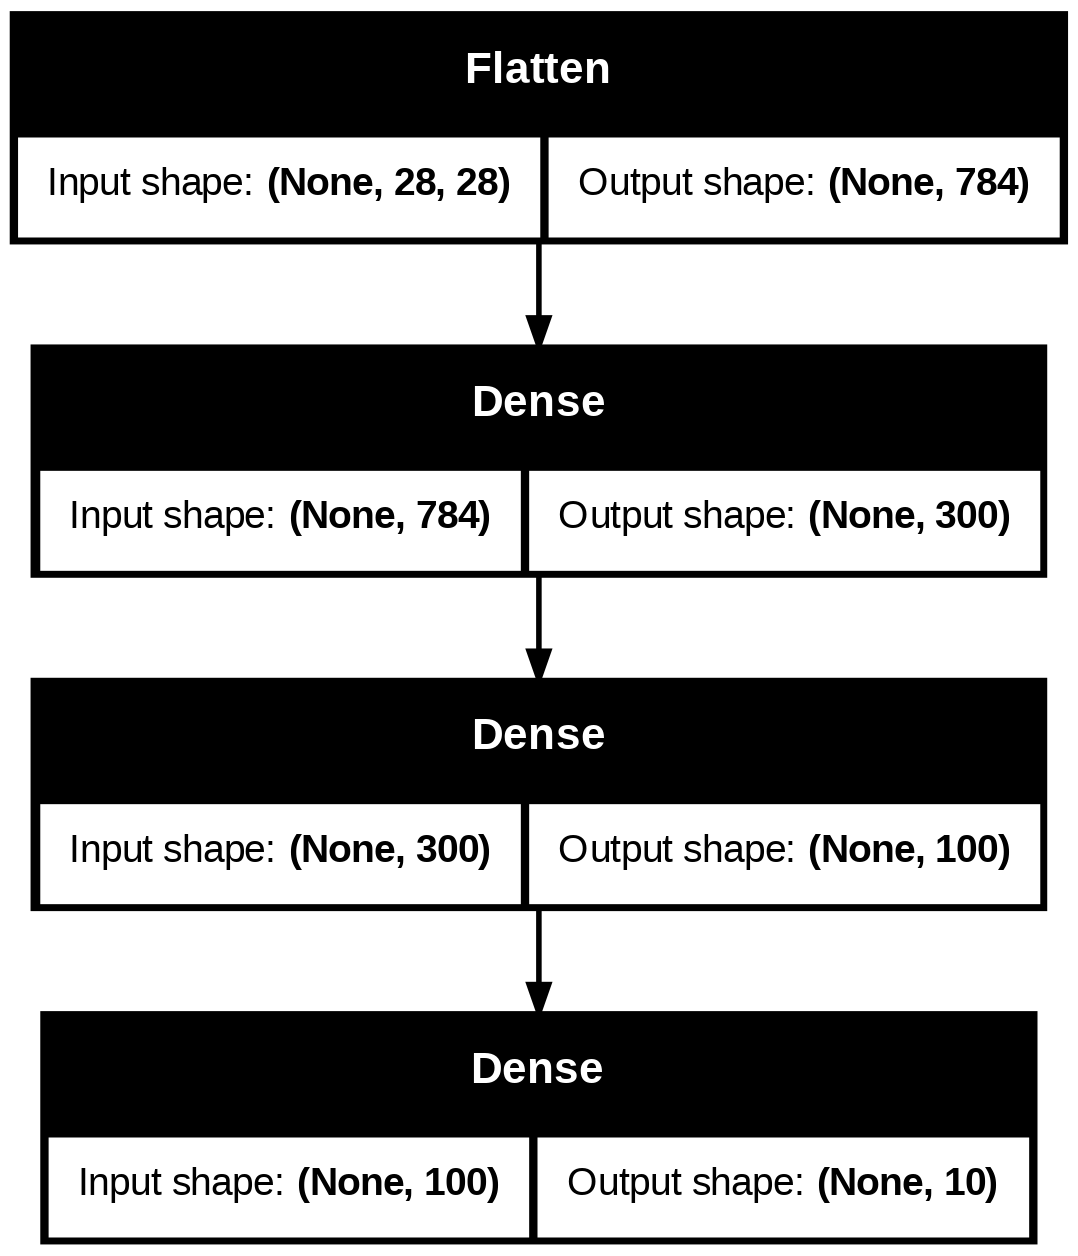

In [ ]:
keras.utils.plot_model(model,"my_fashion_mnist_model.png",show_shapes=True)

In [ ]:
#Compilation informations
model.compile(loss="sparse_categorical_crossentropy"
              ,optimizer="sgd",
              metrics=["accuracy"]
              )

In [ ]:
history=model.fit(X_train,y_train,epochs=30,batch_size=32,validation_data=(X_valid,y_valid),callbacks=[keras.callbacks.EarlyStopping(patience=5)])

Epoch 1/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.6845 - loss: 0.9951 - val_accuracy: 0.8246 - val_loss: 0.5252
Epoch 2/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - accuracy: 0.8245 - loss: 0.5088 - val_accuracy: 0.8530 - val_loss: 0.4376
Epoch 3/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - accuracy: 0.8436 - loss: 0.4493 - val_accuracy: 0.8582 - val_loss: 0.4197
Epoch 4/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 12s 5ms/step - accuracy: 0.8534 - loss: 0.4214 - val_accuracy: 0.8578 - val_loss: 0.4107
Epoch 5/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8585 - loss: 0.4012 - val_accuracy: 0.8674 - val_loss: 0.3839
Epoch 6/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - accuracy: 0.8648 - loss: 0.3825 - val_accuracy: 0.8542 - val_loss: 0.3958
Epoch 7/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - accuracy: 0.8693 - loss: 0.3700 - val_accuracy: 0.8696 - val_loss: 0.3650
Epoch 8/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.8718 - loss: 0.3576

In [ ]:
# Model evaluation
model.evaluate(X_test,y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8802 - loss: 0.3360


[0.33370646834373474, 0.8810999989509583]

In [ ]:
y_test[:3]
#class_names=["T-shirt/top","Trouser","Pullover","Dress","Coat","Sandal","Shirt","Sneaker","Bag","Ankle boot"]

array([9, 2, 1], dtype=uint8)

In [ ]:
#Class prediction
X_new=X_test[:3]
y_proba=model.predict(X_new)
y_proba.round(2) #arrondir les probabilités

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step


array([[0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.02, 0.  , 0.98],
       [0.  , 0.  , 1.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  ],
       [0.  , 1.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  ]],
      dtype=float32)

In [ ]:
X_new=X_test[:3]
y_proba=model.predict(X_new)
y_predict=y_proba.round(2)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step


In [ ]:
#prediction des classes de Y_new
y_pred=np.argmax(y_predict,axis=1)
y_pred

array([9, 2, 1])

In [ ]:
np.array(class_names)[y_pred]

array(['Ankle boot', 'Pullover', 'Trouser'], dtype='<U11')

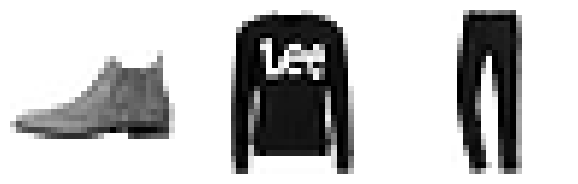

In [ ]:
#Visionner les données X_new
plt.figure(figsize=(7.2,2.4))
for index,image in enumerate(X_new):
  plt.subplot(1,3,index+1)
  plt.imshow(image,cmap="binary",interpolation="nearest")
  plt.axis("off")

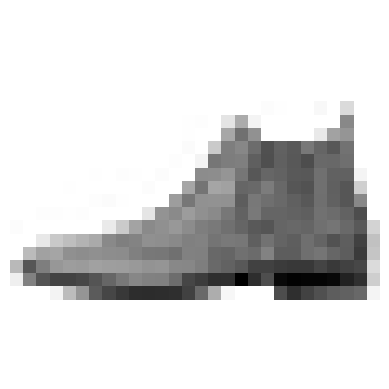

In [ ]:
plt.imshow(X_new[0],cmap="binary")
plt.axis("off")
plt.show()

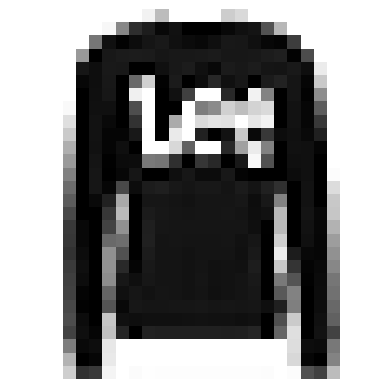

In [ ]:
plt.imshow(X_new[1],cmap="binary")
plt.axis("off")
plt.show()

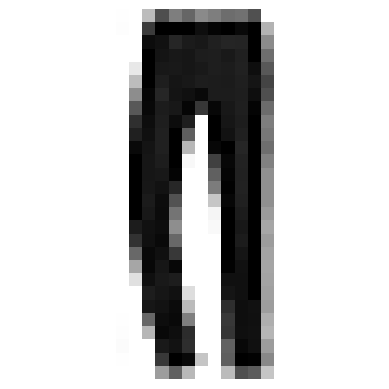

In [ ]:
plt.imshow(X_new[2],cmap="binary")
plt.axis("off")
plt.show()

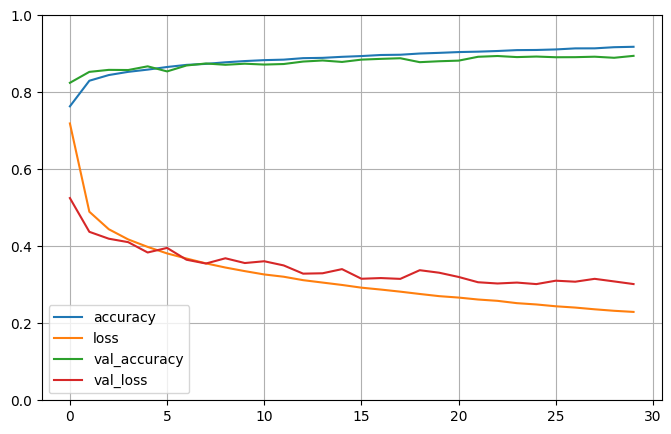

In [ ]:
#Print historical data
import pandas as pd
pd.DataFrame(history.history).plot(figsize=(8,5))
plt.grid(True)
plt.gca().set_ylim(0,1)
plt.show()